In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, f1_score, confusion_matrix


print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.14.6
pandas: 3.0.6
NumPy: 2.5.3
Matplotlib: 3.11.2
scikit-learn: 1.9.1


In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
dataset_path = Path("course_lead_scoring_2026.csv")
source = dataset_path if dataset_path.exists() else url
df_original = pd.read_csv(source)

print("Fonte oficial:", url)
print("Formato:", df_original.shape)
print(df_original.head().to_string(index=False))
print(df_original.dtypes)
print("Ausentes por coluna:")
print(df_original.isna().sum())


Fonte oficial: https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Formato: (5000, 9)
   lead_source      industry employment_status      location  annual_income  number_of_courses_viewed  interaction_count  lead_score  converted
organic_search    technology          employed        europe        88160.0                         3                  4        0.64          1
  social_media    technology          employed south_america        72688.0                         3                  7        0.72          1
      referral        retail          employed        europe        44697.0                         3                  4        0.58          1
      paid_ads manufacturing           student           NaN            NaN                         3                  6        0.57          0
      referral manufacturing           student north_america        24062.0                         4                  5

In [3]:
target = "converted"
features = df_original.columns.drop(target).tolist()
categorical = df_original[features].select_dtypes(exclude="number").columns.tolist()
numerical = df_original[features].select_dtypes(include="number").columns.tolist()
assert df_original[target].notna().all()
assert set(df_original[target].unique()) == {0, 1}

df = df_original.copy()
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)
df[target] = df[target].astype(int)

print("Categóricas:", categorical)
print("Numéricas:", numerical)
print("Ausentes após preparação:")
print(df.isna().sum())
assert df[features].notna().all().all()


Categóricas: ['lead_source', 'industry', 'employment_status', 'location']
Numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Ausentes após preparação:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

assert set(df_train.index).isdisjoint(df_val.index)
assert set(df_full_train.index).isdisjoint(df_test.index)
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()
y_full_train = df_full_train[target].to_numpy()
df_train = df_train[features].copy()
df_val = df_val[features].copy()
df_full_train = df_full_train[features].copy()
df_test = df_test[features].copy()

print("Treino:", df_train.shape, y_train.shape)
print("Validação:", df_val.shape, y_val.shape)
print("Treino completo:", df_full_train.shape)
print("Teste reservado:", df_test.shape)
assert (len(df_train), len(df_val), len(df_test)) == (3000, 1000, 1000)


Treino: (3000, 8) (3000,)
Validação: (1000, 8) (1000,)
Treino completo: (4000, 8)
Teste reservado: (1000, 8)


In [5]:
auc_rows = []
for feature in numerical:
    scores = df_train[feature].to_numpy()
    original_auc = roc_auc_score(y_train, scores)
    inverted = original_auc < 0.5
    if inverted:
        scores = -scores
    adjusted_auc = roc_auc_score(y_train, scores)
    auc_rows.append((feature, original_auc, inverted, adjusted_auc))

auc_features = pd.DataFrame(
    auc_rows, columns=["feature", "auc_original", "inverted", "auc_adjusted"]
).sort_values("auc_adjusted", ascending=False)
q1_answer = auc_features.iloc[0]["feature"]
print(auc_features.to_string(index=False))
print("Q1:", q1_answer)


                 feature  auc_original  inverted  auc_adjusted
              lead_score      0.788225     False      0.788225
       interaction_count      0.764920     False      0.764920
number_of_courses_viewed      0.722989     False      0.722989
           annual_income      0.608198     False      0.608198
Q1: lead_score


In [6]:
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)
prob_val = model.predict_proba(X_val)[:, 1]

print("Matrizes:", X_train.shape, X_val.shape)
print("Classes:", model.classes_)
print("Features codificadas:", dv.get_feature_names_out())
print("Coeficientes e intercepto:", model.coef_.shape, model.intercept_.shape)
print("Primeiras probabilidades:", prob_val[:5])
assert np.array_equal(model.classes_, [0, 1])


Matrizes: (3000, 28) (1000, 28)
Classes: [0 1]
Features codificadas: ['annual_income' 'employment_status=NA' 'employment_status=employed'
 'employment_status=self_employed' 'employment_status=student'
 'employment_status=unemployed' 'industry=NA' 'industry=education'
 'industry=finance' 'industry=healthcare' 'industry=manufacturing'
 'industry=retail' 'industry=technology' 'interaction_count' 'lead_score'
 'lead_source=NA' 'lead_source=events' 'lead_source=organic_search'
 'lead_source=paid_ads' 'lead_source=referral' 'lead_source=social_media'
 'location=NA' 'location=africa' 'location=asia' 'location=europe'
 'location=north_america' 'location=south_america'
 'number_of_courses_viewed']
Coeficientes e intercepto: (1, 28) (1,)
Primeiras probabilidades: [0.54472295 0.79005198 0.50977894 0.52913941 0.82072021]


ROC AUC completa: 0.7318222288173319
Q2: 0.732


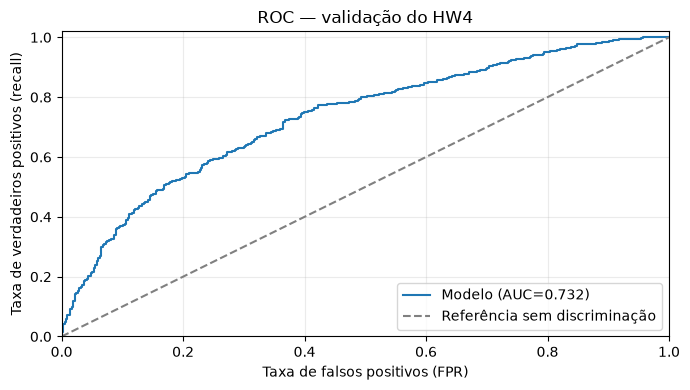

In [7]:
auc_val = roc_auc_score(y_val, prob_val)
q2_answer = round(float(auc_val), 3)
print("ROC AUC completa:", auc_val)
print("Q2:", q2_answer)

fpr, tpr, roc_thresholds = roc_curve(y_val, prob_val)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fpr, tpr, label=f"Modelo (AUC={auc_val:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referência sem discriminação")
ax.set(xlabel="Taxa de falsos positivos (FPR)", ylabel="Taxa de verdadeiros positivos (recall)", title="ROC — validação do HW4", xlim=(0, 1), ylim=(0, 1.02))
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
plt.close(fig)


In [8]:
thresholds = np.linspace(0.0, 1.0, 101)
threshold_rows = []
for threshold in thresholds:
    pred = (prob_val >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)
    threshold_rows.append((threshold, tn, fp, fn, tp, precision, recall, f1))

threshold_metrics = pd.DataFrame(
    threshold_rows, columns=["threshold", "tn", "fp", "fn", "tp", "precision", "recall", "f1"]
)
print(threshold_metrics.head().to_string(index=False))
print("Quantidade de limiares:", len(threshold_metrics))
assert len(threshold_metrics) == 101
assert (threshold_metrics[["tn", "fp", "fn", "tp"]].sum(axis=1) == len(y_val)).all()


 threshold  tn  fp  fn  tp  precision  recall       f1
      0.00   0 414   0 586      0.586     1.0 0.738966
      0.01   0 414   0 586      0.586     1.0 0.738966
      0.02   0 414   0 586      0.586     1.0 0.738966
      0.03   0 414   0 586      0.586     1.0 0.738966
      0.04   0 414   0 586      0.586     1.0 0.738966
Quantidade de limiares: 101


 threshold  tn  fp  fn  tp  precision   recall       f1  absolute_difference
      0.63 259 155 161 425   0.732759 0.725256 0.728988             0.007503
      0.62 249 165 149 437   0.725914 0.745734 0.735690             0.019820
      0.64 263 151 178 408   0.729875 0.696246 0.712664             0.033629
      0.61 237 177 133 453   0.719048 0.773038 0.745066             0.053990
      0.65 277 137 194 392   0.741021 0.668942 0.703139             0.072079
Q3: 0.63


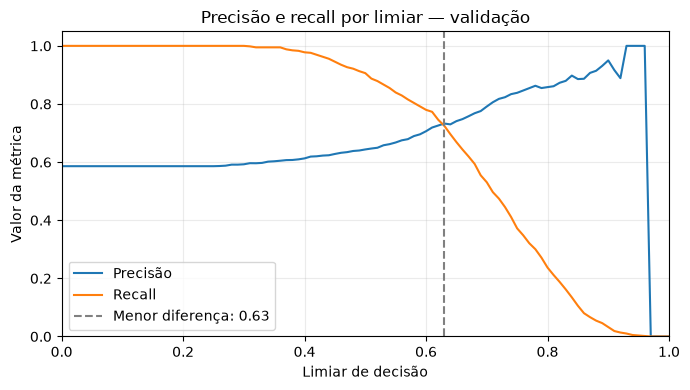

In [9]:
nonzero = threshold_metrics.loc[
    (threshold_metrics["precision"] != 0) | (threshold_metrics["recall"] != 0)
].copy()
nonzero["absolute_difference"] = (nonzero["precision"] - nonzero["recall"]).abs()
intersection = nonzero.sort_values(["absolute_difference", "threshold"]).iloc[0]
q3_answer = round(float(intersection["threshold"]), 2)
print(nonzero.sort_values(["absolute_difference", "threshold"]).head().to_string(index=False))
print("Q3:", q3_answer)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(threshold_metrics["threshold"], threshold_metrics["precision"], label="Precisão")
ax.plot(threshold_metrics["threshold"], threshold_metrics["recall"], label="Recall")
ax.axvline(q3_answer, linestyle="--", color="gray", label=f"Menor diferença: {q3_answer:.2f}")
ax.set(xlabel="Limiar de decisão", ylabel="Valor da métrica", title="Precisão e recall por limiar — validação", xlim=(0, 1), ylim=(0, 1.05))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


 threshold  tn  fp  fn  tp  precision   recall       f1
      0.41  62 352  14 572   0.619048 0.976109 0.757616
      0.42  66 348  18 568   0.620087 0.969283 0.756325
      0.43  72 342  22 564   0.622517 0.962457 0.756032
      0.45  86 328  32 554   0.628118 0.945392 0.754768
      0.44  76 338  26 560   0.623608 0.955631 0.754717
Q4: 0.41


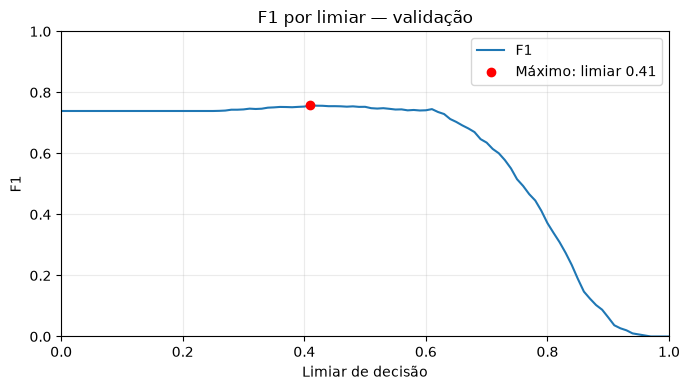

In [10]:
best_f1 = threshold_metrics.sort_values(
    ["f1", "threshold"], ascending=[False, True]
).iloc[0]
q4_answer = round(float(best_f1["threshold"]), 2)
print(threshold_metrics.sort_values(["f1", "threshold"], ascending=[False, True]).head().to_string(index=False))
print("Q4:", q4_answer)

denominator = 2 * threshold_metrics["tp"] + threshold_metrics["fp"] + threshold_metrics["fn"]
f1_from_counts = np.divide(
    2 * threshold_metrics["tp"].to_numpy(), denominator.to_numpy(),
    out=np.zeros(len(threshold_metrics)), where=denominator.to_numpy() != 0
)
assert np.allclose(f1_from_counts, threshold_metrics["f1"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(threshold_metrics["threshold"], threshold_metrics["f1"], label="F1")
ax.scatter([q4_answer], [best_f1["f1"]], color="red", zorder=3, label=f"Máximo: limiar {q4_answer:.2f}")
ax.set(xlabel="Limiar de decisão", ylabel="F1", title="F1 por limiar — validação", xlim=(0, 1), ylim=(0, 1))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


In [11]:
comparison = threshold_metrics.loc[
    np.isclose(threshold_metrics["threshold"], q3_answer)
    | np.isclose(threshold_metrics["threshold"], q4_answer)
].copy()
comparison["predicted_positive"] = comparison["tp"] + comparison["fp"]
print(comparison.to_string(index=False))
print("Convertidos reais na validação:", int(y_val.sum()))
print("Não convertidos reais na validação:", int((y_val == 0).sum()))


 threshold  tn  fp  fn  tp  precision   recall       f1  predicted_positive
      0.41  62 352  14 572   0.619048 0.976109 0.757616                 924
      0.63 259 155 161 425   0.732759 0.725256 0.728988                 580
Convertidos reais na validação: 586
Não convertidos reais na validação: 414


In [12]:
def evaluate_cv(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    rows = []
    for fold, (train_idx, val_idx) in enumerate(kfold.split(df_full_train), start=1):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]
        fold_y_train = y_full_train[train_idx]
        fold_y_val = y_full_train[val_idx]

        fold_dv = DictVectorizer(sparse=False)
        fold_X_train = fold_dv.fit_transform(fold_train.to_dict(orient="records"))
        fold_X_val = fold_dv.transform(fold_val.to_dict(orient="records"))
        fold_model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        fold_model.fit(fold_X_train, fold_y_train)
        fold_prob = fold_model.predict_proba(fold_X_val)[:, 1]
        fold_auc = roc_auc_score(fold_y_val, fold_prob)
        rows.append((fold, len(train_idx), len(val_idx), fold_X_train.shape[1], fold_auc))
    return pd.DataFrame(rows, columns=["fold", "train_rows", "val_rows", "encoded_columns", "auc"])

cv_c1 = evaluate_cv(C=1.0)
print(cv_c1.to_string(index=False))
assert len(cv_c1) == 5
assert (cv_c1["train_rows"] == 3200).all()
assert (cv_c1["val_rows"] == 800).all()


 fold  train_rows  val_rows  encoded_columns      auc
    1        3200       800               28 0.730560
    2        3200       800               28 0.729573
    3        3200       800               28 0.736343
    4        3200       800               28 0.741245
    5        3200       800               28 0.720914


In [13]:
scores_c1 = cv_c1["auc"].to_numpy()
mean_c1 = float(np.mean(scores_c1))
std_c1 = float(np.std(scores_c1, ddof=0))
q5_answer = round(std_c1, 3)
print("Média ROC AUC:", mean_c1)
print("Desvio padrão ROC AUC:", std_c1)
print("Q5:", q5_answer)


Média ROC AUC: 0.7317269710972524
Desvio padrão ROC AUC: 0.006853233151022138
Q5: 0.007


In [14]:
c_values = [0.000001, 0.001, 1.0]
cv_details = {1.0: cv_c1}
tuning_rows = []
for C in c_values:
    if C not in cv_details:
        cv_details[C] = evaluate_cv(C=C)
    scores = cv_details[C]["auc"].to_numpy()
    mean_auc = float(np.mean(scores))
    std_auc = float(np.std(scores, ddof=0))
    tuning_rows.append((C, mean_auc, std_auc, round(mean_auc, 3), round(std_auc, 3)))

tuning = pd.DataFrame(
    tuning_rows, columns=["C", "mean_auc", "std_auc", "mean_rounded", "std_rounded"]
)
ranking = tuning.sort_values(
    ["mean_rounded", "std_rounded", "C"], ascending=[False, True, True]
)
q6_answer = float(ranking.iloc[0]["C"])
print(tuning.to_string(index=False))
print("Q6:", q6_answer)


       C  mean_auc  std_auc  mean_rounded  std_rounded
0.000001  0.616734 0.018670         0.617        0.019
0.001000  0.749172 0.009996         0.749        0.010
1.000000  0.731727 0.006853         0.732        0.007
Q6: 0.001


In [15]:
answers = pd.DataFrame({
    "questao": ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    "resposta": [q1_answer, f"{q2_answer:.3f}", f"{q3_answer:.2f}", f"{q4_answer:.2f}", f"{q5_answer:.3f}", f"{q6_answer:g}"]
})
print(answers.to_string(index=False))


questao   resposta
     Q1 lead_score
     Q2      0.732
     Q3       0.63
     Q4       0.41
     Q5      0.007
     Q6      0.001
